# Astronomy Data Analysis and Star Type Classification
**Data Mining Lab 12 – Final Project**

**Project topic:** Astronomy Data Analysis  
**Dataset:** `astronomy_stars.csv` (included with this notebook)

## Project overview
This project explores a star-catalogue-style dataset, studies relationships among stellar properties, and builds machine-learning models to classify stars into four broad groups: Main Sequence, Giant, Supergiant, and White Dwarf.

> **Dataset note:** The included CSV is a generated educational dataset, not a catalogue of actual telescope observations. Its values are designed to be broadly astronomy-inspired and suitable for demonstrating data mining methods. Do not present its records as real measured stars.

## Objectives
1. Load and understand an astronomy dataset.
2. Clean missing values and duplicate records.
3. Perform descriptive statistics and exploratory data analysis (EDA).
4. Visualize star properties and their relationships.
5. Prepare features without leaking information from the test set.
6. Train and compare classification algorithms.
7. Evaluate the best model and demonstrate a sample prediction.

## Workflow
CSV loading → data inspection → cleaning → EDA → preprocessing → train/test split → model training → evaluation → sample prediction.

## 1. Import required libraries
We use Pandas and NumPy for data handling, Matplotlib and Seaborn for visualization, and Scikit-learn for preprocessing and machine learning.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

sns.set_theme(style="whitegrid")
RANDOM_STATE = 31

## 2. Load the CSV dataset
Keep `astronomy_stars.csv` in the same folder as this notebook. The code also gives a clear error if the file is missing.

In [2]:
DATA_FILE = "astronomy_stars.csv"
df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (1005, 10)


,Star_ID,Temperature_K,Luminosity_Lsun,Radius_Rsun,Absolute_Magnitude,Color_Index,Spectral_Class,Distance_LY,Apparent_Magnitude,Star_Type
0,STAR-0001,4485.8,0.513875,1.12610,5.310,0.985,K,103.95,10.535,Main Sequence
1,STAR-0002,6923.6,4.955509,1.68692,3.536,0.483,F,1764.19,14.888,Main Sequence
2,STAR-0003,7744.3,0.746431,0.45585,5.001,0.186,A,2106.96,16.542,Main Sequence
3,STAR-0004,6076.8,1.008144,1.04448,4.754,0.466,F,1446.34,15.493,Main Sequence
4,STAR-0005,10112.8,14.848731,1.32828,1.723,-0.350,B,106.75,7.034,Main Sequence


## 3. Dataset description and structure
Each row represents one generated star record. `Star_Type` is the target label that the models will predict.

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nDescriptive statistics:")
display(df.describe(include="all").T)

Column names:
['Star_ID', 'Temperature_K', 'Luminosity_Lsun', 'Radius_Rsun', 'Absolute_Magnitude', 'Color_Index', 'Spectral_Class', 'Distance_LY', 'Apparent_Magnitude', 'Star_Type']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Star_ID             1005 non-null   object 
 1   Temperature_K       1005 non-null   float64
 2   Luminosity_Lsun     1000 non-null   float64
 3   Radius_Rsun         1005 non-null   float64
 4   Absolute_Magnitude  1005 non-null   float64
 5   Color_Index         997 non-null    float64
 6   Spectral_Class      1005 non-null   object 
 7   Distance_LY         999 non-null    float64
 8   Apparent_Magnitude  1005 non-null   float64
 9   Star_Type           1005 non-null   object 
dtypes: float64(7), object(3)
memory usage: 78.6+ KB
\nDescriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Star_ID,1005,1000,STAR-0976,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temperature_K,1005.0,NaN,NaN,NaN,10654.56209,7804.459485,2500.0,4394.3,7383.5,15408.9,35000.0
Luminosity_Lsun,1000.0,NaN,NaN,NaN,516948.657929,2267369.4475,0.000112,0.049973,4.785416,77.472283,20000000.0
Radius_Rsun,1005.0,NaN,NaN,NaN,24.19057,50.492039,0.00575,0.40458,1.29313,13.20799,339.72649
Absolute_Magnitude,1005.0,NaN,NaN,NaN,2.719192,6.670983,-14.048,0.196,3.041,7.99,15.116
Color_Index,997.0,NaN,NaN,NaN,0.320274,0.643295,-0.35,-0.35,0.257,0.943,1.556
Spectral_Class,1005,7,B,405,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distance_LY,999.0,NaN,NaN,NaN,1257.2102,727.887706,5.45,598.09,1296.9,1884.78,2495.49
Apparent_Magnitude,1005.0,NaN,NaN,NaN,12.576232,7.051262,-10.569,9.43,13.093,18.194,25.654
Star_Type,1005,4,Main Sequence,361,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data quality check
Check missing values, duplicate rows, and target categories before analysis.

In [4]:
print("Missing values by column:")
display(df.isnull().sum().to_frame("Missing_Count"))

print("Duplicate rows:", df.duplicated().sum())

print("Star type distribution:")
display(df["Star_Type"].value_counts())

Missing values by column:


,Missing_Count
Star_ID,0
Temperature_K,0
Luminosity_Lsun,5
Radius_Rsun,0
Absolute_Magnitude,0
Color_Index,8
Spectral_Class,0
Distance_LY,6
Apparent_Magnitude,0
Star_Type,0


Duplicate rows: 5
Star type distribution:


Star_Type
Main Sequence    361
White Dwarf      243
Giant            241
Supergiant       160
Name: count, dtype: int64

## 5. Data cleaning
We remove exact duplicate rows. Missing numeric values are filled with the median and missing categorical values with the most frequent category. These imputers are later placed inside the ML pipeline so they are fitted only on the training data.

In [5]:
df_clean = df.drop_duplicates().copy()

print("Shape before cleaning:", df.shape)
print("Shape after removing duplicates:", df_clean.shape)
print("Remaining missing values:")
display(df_clean.isnull().sum().to_frame("Missing_Count"))

Shape before cleaning: (1005, 10)
Shape after removing duplicates: (1000, 10)
Remaining missing values:


,Missing_Count
Star_ID,0
Temperature_K,0
Luminosity_Lsun,5
Radius_Rsun,0
Absolute_Magnitude,0
Color_Index,8
Spectral_Class,0
Distance_LY,6
Apparent_Magnitude,0
Star_Type,0


## 6. Exploratory Data Analysis (EDA)
### 6.1 Distribution of star types
The bar chart shows how many examples belong to each class.

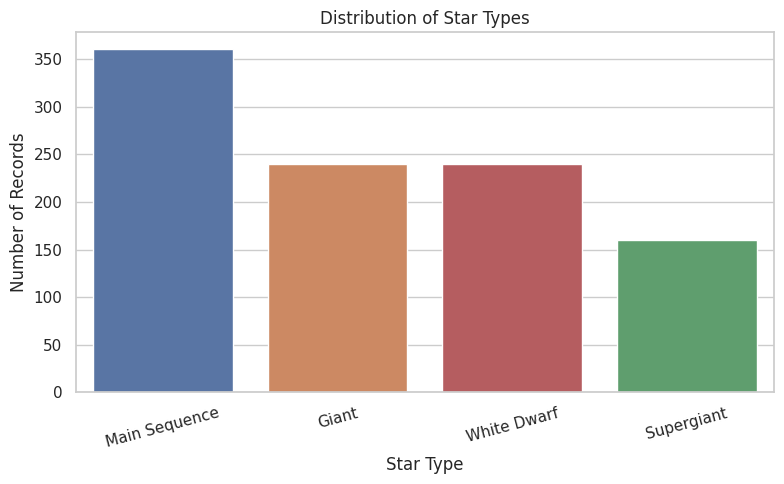

In [6]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="Star_Type", hue="Star_Type", palette="deep", legend=False, order=df_clean["Star_Type"].value_counts().index)
plt.title("Distribution of Star Types")
plt.xlabel("Star Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 6.2 Stellar temperature distribution

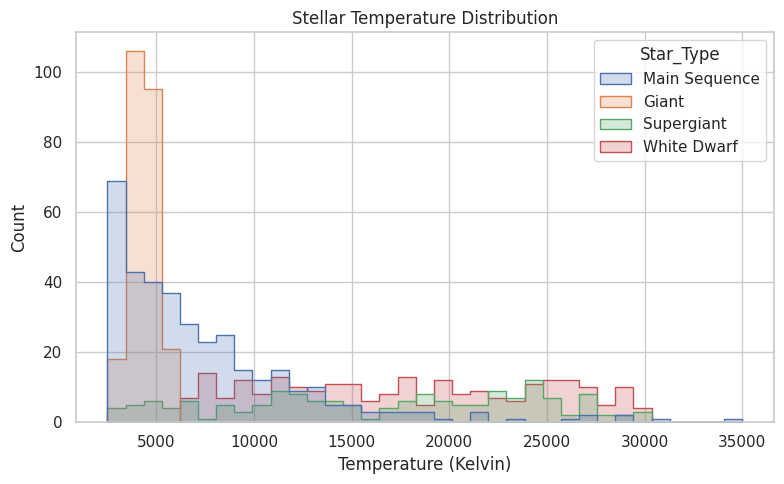

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Temperature_K", hue="Star_Type", bins=35, element="step", stat="count", common_norm=False, palette="deep")
plt.title("Stellar Temperature Distribution")
plt.xlabel("Temperature (Kelvin)")
plt.tight_layout()
plt.show()

### 6.3 Luminosity and radius by star type

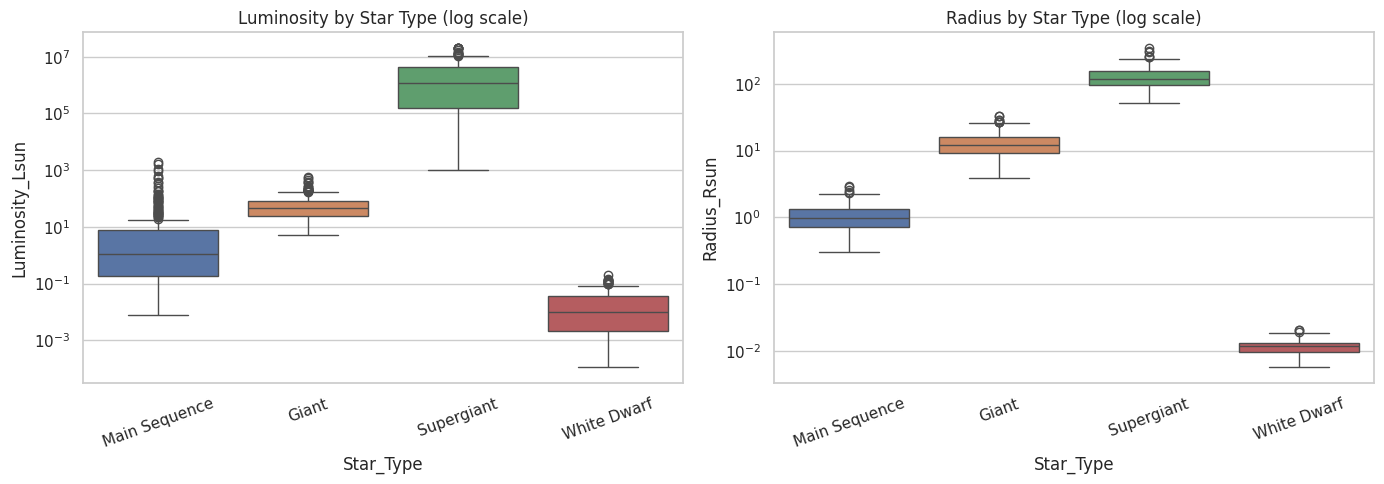

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df_clean, x="Star_Type", y="Luminosity_Lsun", hue="Star_Type", palette="deep", legend=False, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Luminosity by Star Type (log scale)")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=df_clean, x="Star_Type", y="Radius_Rsun", hue="Star_Type", palette="deep", legend=False, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Radius by Star Type (log scale)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 6.4 Temperature versus luminosity

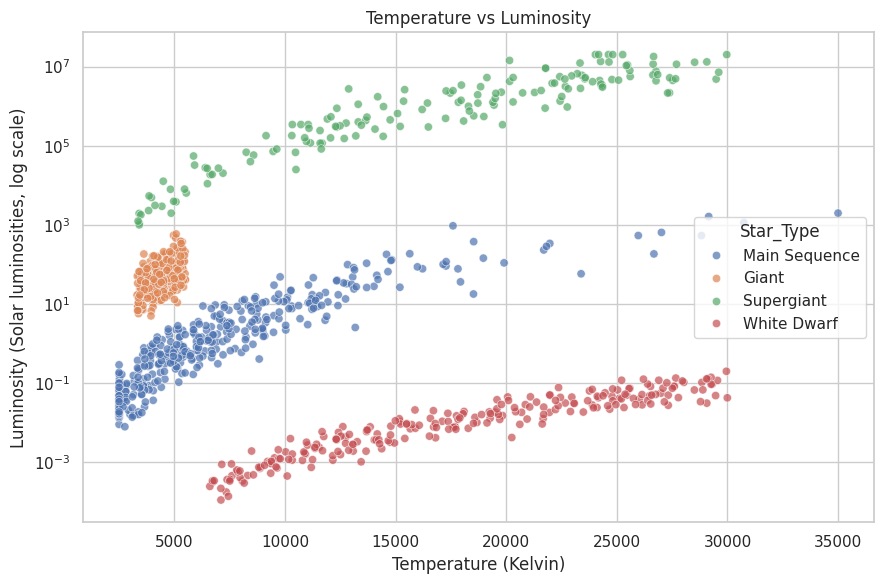

In [9]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_clean, x="Temperature_K", y="Luminosity_Lsun", hue="Star_Type", palette="deep", alpha=0.7)
plt.yscale("log")
plt.title("Temperature vs Luminosity")
plt.xlabel("Temperature (Kelvin)")
plt.ylabel("Luminosity (Solar luminosities, log scale)")
plt.tight_layout()
plt.show()

## 7. Correlation analysis
Correlation is calculated for numeric columns only. It measures linear association and does not prove causation.

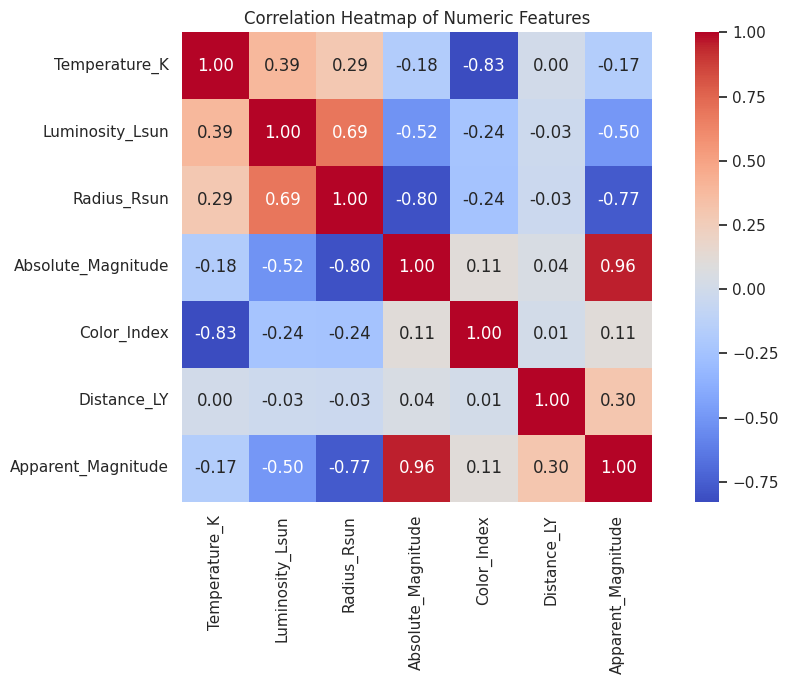

In [10]:
numeric_df = df_clean.select_dtypes(include=np.number)
corr = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

## 8. Feature preparation and feature importance
`Star_ID` is an identifier, so it is not used as a predictive feature. `Star_Type` is the target. We use the remaining columns as input features.

The feature-importance plot below is exploratory. The model evaluation later uses a held-out test set.

,Importance
Radius_Rsun,0.335024
Absolute_Magnitude,0.184174
Luminosity_Lsun,0.157981
Apparent_Magnitude,0.106668
Temperature_K,0.078931
Color_Index,0.071884
Spectral_Class_B,0.031953
Spectral_Class_K,0.012836
Spectral_Class_M,0.010611
Distance_LY,0.003714


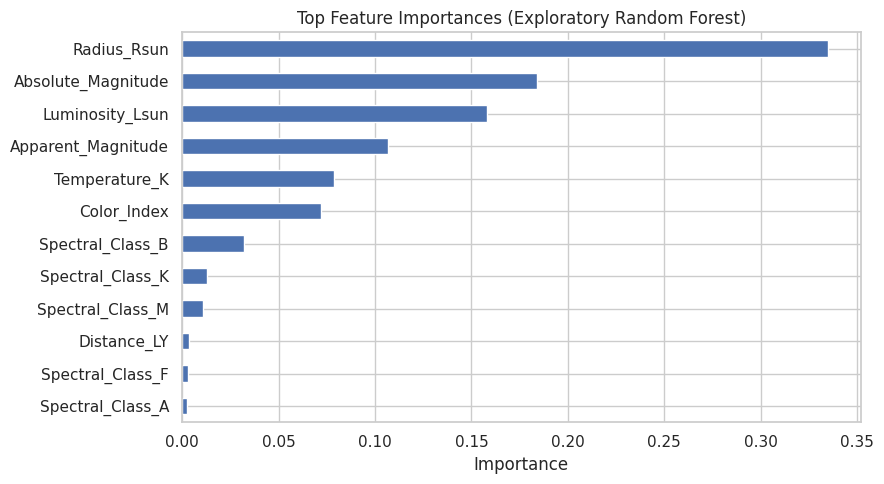

In [11]:
target = "Star_Type"
X = df_clean.drop(columns=[target, "Star_ID"])
y = df_clean[target]

# Use a simple Random Forest to inspect feature importance.
# Missing values are filled here only for this exploratory importance calculation.
X_importance = X.copy()
for col in X_importance.select_dtypes(include=np.number).columns:
    X_importance[col] = X_importance[col].fillna(X_importance[col].median())
for col in X_importance.select_dtypes(exclude=np.number).columns:
    X_importance[col] = X_importance[col].fillna(X_importance[col].mode()[0])
X_importance = pd.get_dummies(X_importance, drop_first=False)

importance_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
importance_model.fit(X_importance, y)

importance = pd.Series(importance_model.feature_importances_, index=X_importance.columns).sort_values(ascending=False)
display(importance.head(12).to_frame("Importance"))

plt.figure(figsize=(9, 5))
importance.head(12).sort_values().plot(kind="barh")
plt.title("Top Feature Importances (Exploratory Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 9. Train-test split and preprocessing
We split the data before fitting preprocessing steps. Numeric features are median-imputed and standardized; categorical features are mode-imputed and one-hot encoded. A Pipeline ensures the transformations are learned from training data only.

In [12]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Training records: 800
Testing records: 200
Numeric features: ['Temperature_K', 'Luminosity_Lsun', 'Radius_Rsun', 'Absolute_Magnitude', 'Color_Index', 'Distance_LY', 'Apparent_Magnitude']
Categorical features: ['Spectral_Class']


## 10. Train multiple classification models
We compare five standard algorithms. All models use the same preprocessing pipeline and the same train/test split.

In [13]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=250, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7),
    "Support Vector Machine": SVC(kernel="rbf", C=2.0),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

trained_models = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)
    score = accuracy_score(y_test, predictions)
    trained_models[name] = pipe
    results.append({"Model": name, "Accuracy": score})

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(results_df)

,Model,Accuracy
0,Decision Tree,1.000
1,Random Forest,1.000
2,Support Vector Machine,1.000
3,Gradient Boosting,1.000
4,K-Nearest Neighbors,0.995


### 10.1 Model accuracy comparison

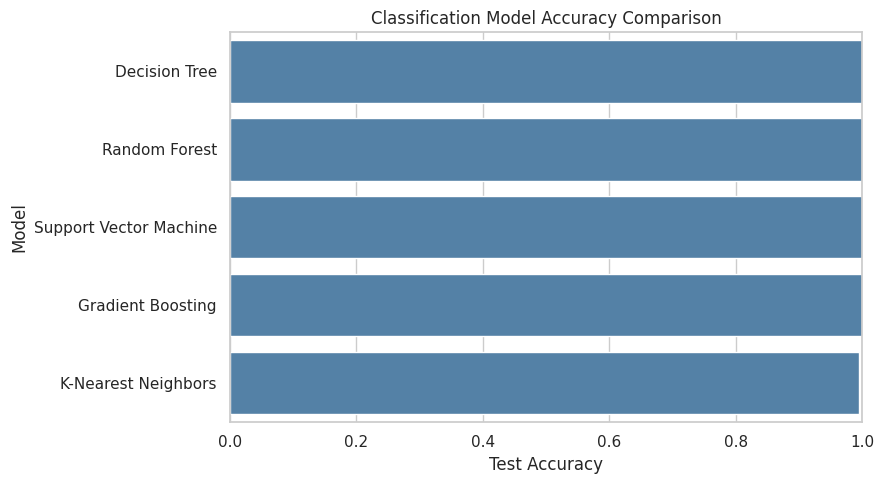

In [14]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Accuracy", y="Model", color="steelblue")
plt.xlim(0, 1.0)
plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Test Accuracy")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

## 11. Evaluate the best-performing model
Accuracy is useful, but it should be considered together with precision, recall, F1-score, and the confusion matrix.

Best model: Decision Tree
Test accuracy: 1.0
\nClassification report:
               precision    recall  f1-score   support

        Giant       1.00      1.00      1.00        48
Main Sequence       1.00      1.00      1.00        72
   Supergiant       1.00      1.00      1.00        32
  White Dwarf       1.00      1.00      1.00        48

     accuracy                           1.00       200
    macro avg       1.00      1.00      1.00       200
 weighted avg       1.00      1.00      1.00       200



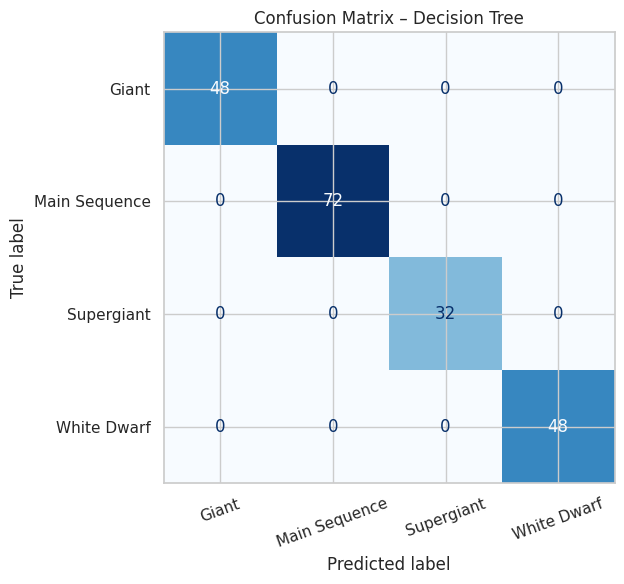

In [15]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Best model:", best_model_name)
print("Test accuracy:", round(accuracy_score(y_test, best_predictions), 4))
print("\\nClassification report:")
print(classification_report(y_test, best_predictions, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, best_predictions, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=20, colorbar=False)
plt.title(f"Confusion Matrix – {best_model_name}")
plt.tight_layout()
plt.show()

## 12. Make a sample prediction
The example below takes one record from the test set and predicts its star type. This is a demonstration using a held-out row, not a new telescope observation.

In [16]:
sample_star = X_test.iloc[[0]]
actual_type = y_test.iloc[0]
predicted_type = best_model.predict(sample_star)[0]

display(sample_star)
print("Actual star type:", actual_type)
print("Predicted star type:", predicted_type)

,Temperature_K,Luminosity_Lsun,Radius_Rsun,Absolute_Magnitude,Color_Index,Spectral_Class,Distance_LY,Apparent_Magnitude
471,3844.4,71.052896,16.82132,0.66,1.129,K,2285.44,12.298


Actual star type: Giant
Predicted star type: Giant


## 13. Conclusion
In this project, we loaded and cleaned an astronomy-inspired star dataset, explored stellar properties using charts, examined numeric correlations, and compared several classification algorithms. The best model was selected using test-set accuracy and then examined using a classification report and confusion matrix.

**Important limitation:** The supplied CSV is synthetic and intended for learning. Model performance on this generated dataset does not establish performance on real astronomical observations. For scientific use, the workflow should be repeated with a documented real catalogue and carefully validated labels.

## 14. Ideas for future improvement
- Replace the generated dataset with a documented catalogue from a public astronomy archive.
- Add cross-validation and hyperparameter tuning.
- Study star clusters or exoplanet properties as a separate analysis.
- Validate predictions against expert-labelled real observations.

---
**End of Lab 12 – Astronomy Data Analysis**